# **AI101 Mini-Project: Spotify Popularity Prediction (Expanded Version)**
### **Group 13: Hit Song Popularity Prediction (Regression)**
*Course:* AI101 - Data Science and AI Essentials with Python, sAIDE, IIT Ropar

---
## **Team Members, Deliverables & Section Ownership**

| Member | Name | Entry No. | Deliverable Lead | Coding Task | Notebook Section Owned |
| :---: | :--- | :---: | :--- | :--- | :--- |
| **Member 1** | **Hemanshu Samadhan Borse** | `2026ESB1477` | **Documentation lead** | Data cleaning and preprocessing | **Section 2: Data Preprocessing (Full `src/preprocess.py`)** |
| **Member 2** | **Kayalvizhi S U** | `2026EEB1364` | **PPT lead** | Exploratory Data Analysis (EDA) and graphs | **Section 3: Exploratory Data Analysis (Full `src/eda.py`)** |
| **Member 3** | **Mannat** | `2026AIB1056` | **Video lead** | Linear Regression model | **Section 4 & 5: Feature Scaling & Model Training (Full `src/train_model.py`)** |
| **Member 4** | **Aaditya Chandel** | `2026MCB1502` | **Execution lead** | Model evaluation, integration and running the complete project | **Section 1, 6, 7 & 8: Evaluation, Diagnostics & Integration (`src/evaluation.py` & `src/main.py`)** |

> *This expanded version contains 100% of every function, exploratory graph, invalid check, and diagnostic line from all four source modules in `src/`.*

---

## **Section 1: Setup, Paths & Environment Integration**
* **Lead:** **Aaditya Chandel** (Execution lead - Member 4)
* **Coding Task:** Model evaluation, integration and running the complete project
* **Source Module:** `src/main.py`

Imports all libraries, verifies candidate paths for the dataset, and sets up portable path resolution.

In [1]:
import os
import sys
import time
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Machine learning imports
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, root_mean_squared_error, r2_score

# Visual formatting
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams["figure.figsize"] = (8, 6)

# Robust candidate dataset path resolution from src/main.py
ROOT_DIR = Path("..") if Path("../data").exists() else Path(".")
candidates = [
    ROOT_DIR / "data" / "dataset.csv",
    ROOT_DIR / "data" / "spotify-tracks-dataset.csv",
    ROOT_DIR / "dataset.csv"
]
DATA_PATH = None
for p in candidates:
    if p.exists():
        DATA_PATH = p
        break

OUT_DIR = ROOT_DIR / "outputs"
OUT_DIR.mkdir(parents=True, exist_ok=True)

print("Project root resolved:", ROOT_DIR.resolve())
print("Dataset path resolved:", DATA_PATH.resolve() if DATA_PATH else "NOT FOUND")
print("Outputs directory    :", OUT_DIR.resolve())

Project root resolved: C:\Users\aadit\OneDrive\Desktop\Ai101 Project\ai101-team--13-spotify-popularity-predictor
Dataset path resolved: C:\Users\aadit\OneDrive\Desktop\Ai101 Project\ai101-team--13-spotify-popularity-predictor\data\dataset.csv
Outputs directory    : C:\Users\aadit\OneDrive\Desktop\Ai101 Project\ai101-team--13-spotify-popularity-predictor\outputs


## **Section 2: Data Cleaning and Preprocessing**
* **Lead:** **Hemanshu Samadhan Borse** (Documentation lead - Member 1)
* **Coding Task:** Data cleaning and preprocessing
* **Source Module:** `src/preprocess.py`

Contains the full implementation of invalid boundary masks, duplicate detection across genres, and tracking each cleaning step into `cleaning_summary.csv`.

In [2]:
UNIT_RANGE = [
    "danceability", "energy", "speechiness", "acousticness",
    "instrumentalness", "liveness", "valence"
]

def invalid_mask(df):
    """
    Identifies invalid records:
    - Popularity outside 0-100
    - Unit range audio features outside 0-1
    - Non-positive duration or tempo
    """
    bad = ~df["popularity"].between(0, 100)
    for col in UNIT_RANGE:
        if col in df.columns:
            bad |= ~df[col].between(0, 1)
    if "duration_ms" in df.columns:
        bad |= df["duration_ms"] <= 0
    if "tempo" in df.columns:
        bad |= df["tempo"] <= 0
    return bad

# Load raw data
df_raw = pd.read_csv(DATA_PATH)
rows_before, cols_before = df_raw.shape
print(f"Raw dataset shape: {rows_before:,} rows x {cols_before} columns")

# Execute full cleaning pipeline with audit log
df = df_raw.copy()
log = [("Original dataset", len(df), df.shape[1])]

# a) Drop unnamed index columns
unnamed_cols = [c for c in df.columns if c.startswith("Unnamed")]
if unnamed_cols:
    df = df.drop(columns=unnamed_cols)
log.append(("Drop unnamed index column(s)", len(df), df.shape[1]))

# b) Drop rows with missing values
df = df.dropna()
log.append(("Drop rows with missing values", len(df), df.shape[1]))

# c) Drop fully identical rows
if "track_genre" in df.columns:
    df["track_genre"] = df["track_genre"].str.strip()
df = df.drop_duplicates()
log.append(("Drop fully identical rows", len(df), df.shape[1]))

# d) Drop repeats of same track within same genre
if "track_id" in df.columns and "track_genre" in df.columns:
    df = df.drop_duplicates(subset=["track_id", "track_genre"], keep="first")
log.append(("Drop repeated track_id within the same genre", len(df), df.shape[1]))

# e) Drop invalid records
df = df[~invalid_mask(df)]
log.append(("Drop invalid records", len(df), df.shape[1]))

# f) Make explicit numeric (0/1)
if "explicit" in df.columns and df["explicit"].dtype == bool:
    df["explicit"] = df["explicit"].astype(int)

df = df.reset_index(drop=True)

summary_df = pd.DataFrame(log, columns=["step", "rows_after", "columns_after"])
summary_df["rows_removed"] = (-summary_df["rows_after"].diff()).fillna(0).astype(int)

# Save cleaning summary
summary_df.to_csv(OUT_DIR / "cleaning_summary.csv", index=False)
print(f"Cleaned dataset size: {df.shape[0]:,} rows x {df.shape[1]} columns ({rows_before - df.shape[0]:,} rows removed)")
print(f"Cleaning summary saved to: {OUT_DIR / 'cleaning_summary.csv'}")
summary_df

Raw dataset shape: 114,000 rows x 22 columns
Cleaned dataset size: 113,392 rows x 20 columns (608 rows removed)
Cleaning summary saved to: ..\outputs\cleaning_summary.csv


,step,rows_after,columns_after,rows_removed
0,Original dataset,114000,22,0
1,Drop unnamed index column(s),114000,20,0
2,Drop rows with missing values,113999,20,1
3,Drop fully identical rows,113549,20,450
4,Drop repeated track_id within the same genre,113549,20,0
5,Drop invalid records,113392,20,157


## **Section 3: Exploratory Data Analysis (EDA) and Graphs**
* **Lead:** **Kayalvizhi S U** (PPT lead - Member 2)
* **Coding Task:** Exploratory Data Analysis (EDA) and graphs
* **Source Module:** `src/eda.py`

Contains every single exploratory analysis from `src/eda.py`:
- Dataset overview & summary statistics
- Distribution of Track Popularity histogram
- Top 10 Genres by Average Track Popularity horizontal bar chart
- Danceability vs Popularity & Energy vs Popularity scatter plots
- Pearson Correlation Heatmap across all audio features
- Explicit vs Non-Explicit Popularity comparison bar chart
- Duration in minutes calculation & summary rankings

In [3]:
# 1. Dataset Overview & Numerical Summary
print("Column names:", df.columns.tolist())
print("\nMissing values per column:\n", df.isnull().sum())
print(f"\nDuplicate rows: {df.duplicated().sum()} | Duplicate track_ids: {df['track_id'].duplicated().sum():,}")
print(f"Rows with zero duration: {(df['duration_ms'] == 0).sum()}")
print(f"Popularity Mean: {df['popularity'].mean():.2f} | Median: {df['popularity'].median()} | Min: {df['popularity'].min()} | Max: {df['popularity'].max()}")
df.describe()

Column names: ['track_id', 'artists', 'album_name', 'track_name', 'popularity', 'duration_ms', 'explicit', 'danceability', 'energy', 'key', 'loudness', 'mode', 'speechiness', 'acousticness', 'instrumentalness', 'liveness', 'valence', 'tempo', 'time_signature', 'track_genre']

Missing values per column:
 track_id            0
artists             0
album_name          0
track_name          0
popularity          0
duration_ms         0
explicit            0
danceability        0
energy              0
key                 0
loudness            0
mode                0
speechiness         0
acousticness        0
instrumentalness    0
liveness            0
valence             0
tempo               0
time_signature      0
track_genre         0
dtype: int64

Duplicate rows: 0 | Duplicate track_ids: 23,809
Rows with zero duration: 0
Popularity Mean: 33.32 | Median: 35.0 | Min: 0 | Max: 100


,popularity,duration_ms,explicit,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature
count,113392.00000,1.133920e+05,113392.000000,113392.000000,113392.00000,113392.000000,113392.000000,113392.000000,113392.000000,113392.000000,113392.000000,113392.000000,113392.000000,113392.000000,113392.000000
mean,33.31907,2.281593e+05,0.085703,0.567816,0.64281,5.309537,-8.224233,0.637796,0.084792,0.313811,0.155018,0.213279,0.474862,122.344906,3.909623
std,22.29502,1.054097e+05,0.279926,0.172240,0.25031,3.559564,4.975373,0.480639,0.105788,0.331720,0.308549,0.190011,0.258781,29.646680,0.407246
min,0.00000,1.580000e+04,0.000000,0.051300,0.00002,0.000000,-46.591000,0.000000,0.022100,0.000000,0.000000,0.009250,0.000000,30.200000,0.000000
25%,17.00000,1.743330e+05,0.000000,0.457000,0.47400,2.000000,-9.981000,0.000000,0.035900,0.016800,0.000000,0.097900,0.261000,99.506000,4.000000
50%,35.00000,2.130660e+05,0.000000,0.581000,0.68600,5.000000,-6.990000,1.000000,0.049000,0.168000,0.000041,0.132000,0.464000,122.028000,4.000000
75%,50.00000,2.616500e+05,0.000000,0.695000,0.85400,8.000000,-4.998000,1.000000,0.084600,0.595000,0.047200,0.273000,0.683000,140.081000,4.000000
max,100.00000,5.237295e+06,1.000000,0.985000,1.00000,11.000000,4.532000,1.000000,0.965000,0.996000,1.000000,1.000000,0.995000,243.372000,5.000000


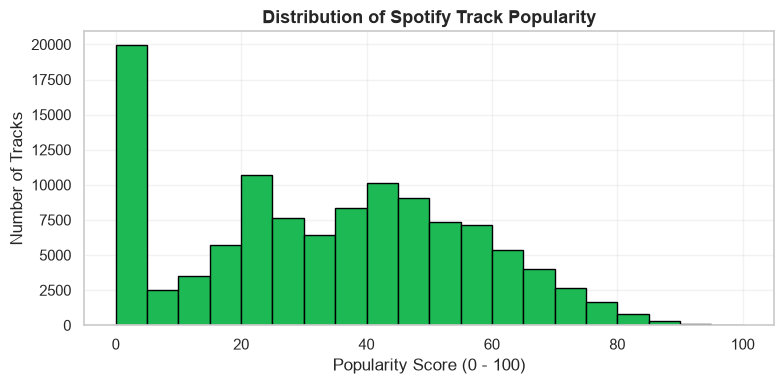

In [4]:
# 2. Distribution of Spotify Track Popularity
plt.figure(figsize=(8, 4))
plt.hist(df["popularity"], bins=20, edgecolor="black", color="#1DB954")
plt.title("Distribution of Spotify Track Popularity", fontsize=13, weight="bold")
plt.xlabel("Popularity Score (0 - 100)")
plt.ylabel("Number of Tracks")
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

Top 10 genres by average popularity:
  track_genre  average_popularity
0    pop-film           59.280280
1       k-pop           56.963928
2       chill           53.704705
3         sad           52.379000
4      grunge           49.582583
5      indian           49.528529
6       anime           48.766767
7         emo           48.128000
8         pop           47.903323
9   sertanejo           47.866000


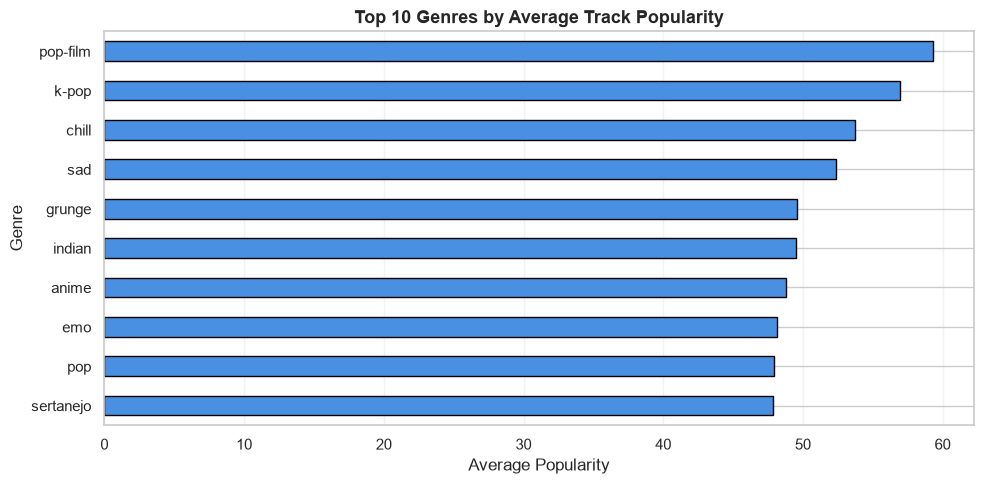

In [5]:
# 3. Top 10 Genres by Average Track Popularity
genre_popularity = df.groupby("track_genre")["popularity"].mean().sort_values(ascending=False)
top_10_genres = genre_popularity.head(10)
print("Top 10 genres by average popularity:")
print(top_10_genres.reset_index(name="average_popularity"))

plt.figure(figsize=(10, 5))
top_10_genres.sort_values().plot(kind="barh", edgecolor="black", color="#4A90E2")
plt.title("Top 10 Genres by Average Track Popularity", fontsize=13, weight="bold")
plt.xlabel("Average Popularity")
plt.ylabel("Genre")
plt.grid(axis="x", alpha=0.25)
plt.tight_layout()
plt.show()

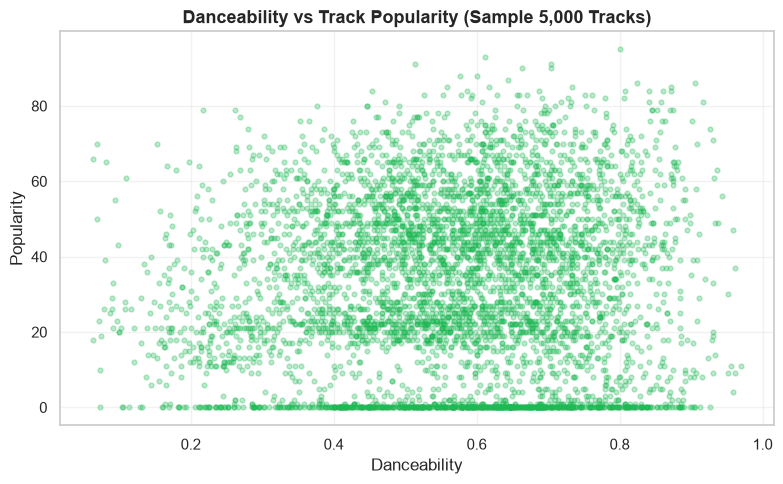

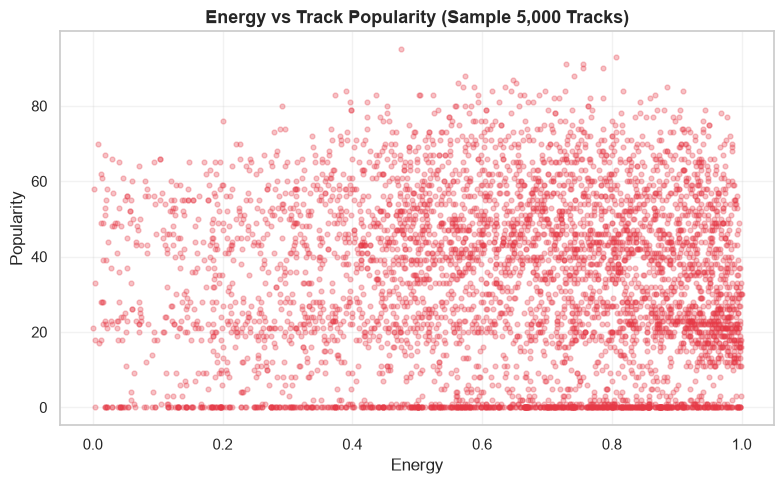

In [6]:
# 4. Danceability vs Popularity and Energy vs Popularity
plot_sample = df.sample(n=min(5000, len(df)), random_state=42)

plt.figure(figsize=(8, 5))
plt.scatter(plot_sample["danceability"], plot_sample["popularity"], alpha=0.3, s=12, color="#1DB954")
plt.title("Danceability vs Track Popularity (Sample 5,000 Tracks)", fontsize=13, weight="bold")
plt.xlabel("Danceability")
plt.ylabel("Popularity")
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

plt.figure(figsize=(8, 5))
plt.scatter(plot_sample["energy"], plot_sample["popularity"], alpha=0.3, s=12, color="#E63946")
plt.title("Energy vs Track Popularity (Sample 5,000 Tracks)", fontsize=13, weight="bold")
plt.xlabel("Energy")
plt.ylabel("Popularity")
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

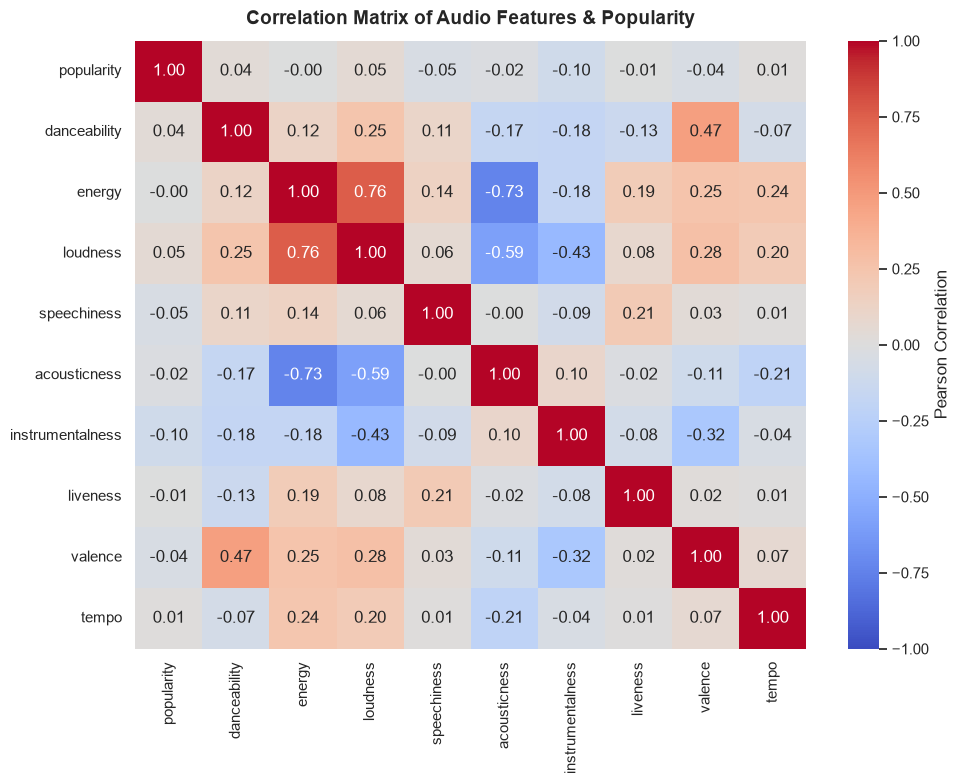

Saved correlation matrix heatmap to: ..\outputs\correlation_matrix.png


In [7]:
# 5. Pearson Correlation Matrix Heatmap
AUDIO_FEATURES = [
    "danceability", "energy", "loudness", "speechiness",
    "acousticness", "instrumentalness", "liveness", "valence", "tempo"
]
available_features = [f for f in AUDIO_FEATURES if f in df.columns]

corr = df[["popularity"] + available_features].corr()

plt.figure(figsize=(10, 8))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, cbar_kws={'label': 'Pearson Correlation'})
plt.title("Correlation Matrix of Audio Features & Popularity", fontsize=14, weight="bold", pad=12)
plt.tight_layout()

corr_path = OUT_DIR / "correlation_matrix.png"
plt.savefig(corr_path, dpi=300)
plt.show()
print(f"Saved correlation matrix heatmap to: {corr_path}")

Average popularity by explicit label:
explicit
0    33.018577
1    36.524799
Name: popularity, dtype: float64


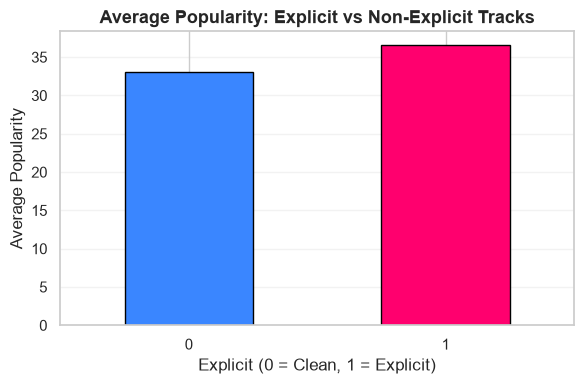

Average duration (minutes): 3.80
Median duration (minutes) : 3.55
                   track_name                 artists  duration_ms  \
0                      Comedy             Gen Hoshino       230666   
1            Ghost - Acoustic            Ben Woodward       149610   
2              To Begin Again  Ingrid Michaelson;ZAYN       210826   
3  Can't Help Falling In Love            Kina Grannis       201933   
4                     Hold On        Chord Overstreet       198853   

   duration_min  
0      3.844433  
1      2.493500  
2      3.513767  
3      3.365550  
4      3.314217  

--- TOP 5 GENRES BY POPULARITY ---
track_genre
pop-film    59.28
k-pop       56.96
chill       53.70
sad         52.38
grunge      49.58
Name: popularity, dtype: float64

--- FEATURES MOST POSITIVELY CORRELATED ---
loudness        0.048
danceability    0.035
tempo           0.013
Name: popularity, dtype: float64

--- FEATURES MOST NEGATIVELY CORRELATED ---
valence            -0.041
speechiness        

In [8]:
# 6. Explicit vs Non-Explicit Popularity & Duration in Minutes
explicit_popularity = df.groupby("explicit")["popularity"].mean()
print("Average popularity by explicit label:")
print(explicit_popularity)

plt.figure(figsize=(6, 4))
explicit_popularity.plot(kind="bar", edgecolor="black", color=["#3A86FF", "#FF006E"])
plt.title("Average Popularity: Explicit vs Non-Explicit Tracks", fontsize=13, weight="bold")
plt.xlabel("Explicit (0 = Clean, 1 = Explicit)")
plt.ylabel("Average Popularity")
plt.xticks(rotation=0)
plt.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()

# Calculate duration in minutes
df["duration_min"] = df["duration_ms"] / 60000
print(f"Average duration (minutes): {df['duration_min'].mean():.2f}")
print(f"Median duration (minutes) : {df['duration_min'].median():.2f}")
print(df[["track_name", "artists", "duration_ms", "duration_min"]].head(5))

print("\n--- TOP 5 GENRES BY POPULARITY ---")
print(genre_popularity.head(5).round(2))
correlation_with_pop = corr["popularity"].drop("popularity").sort_values(ascending=False)
print("\n--- FEATURES MOST POSITIVELY CORRELATED ---")
print(correlation_with_pop.head(3).round(3))
print("\n--- FEATURES MOST NEGATIVELY CORRELATED ---")
print(correlation_with_pop.tail(3).round(3))

## **Section 4 & 5: Feature Scaling, Split & Linear Regression Training**
* **Lead:** **Mannat** (Video lead - Member 3)
* **Coding Task:** Linear Regression model
* **Source Module:** `src/train_model.py`

Extracts the 9 acoustic predictors, partitions 80/20 train-test, standardizes with `StandardScaler`, and trains Multiple Linear Regression with OLS.

In [9]:
# 1. Feature selection and train-test split
features = [
    "danceability", "energy", "loudness", "speechiness",
    "acousticness", "instrumentalness", "liveness", "valence",
    "tempo", "duration_ms"
]
available_features = [f for f in features if f in df.columns]

X = df[available_features].copy()
y = df["popularity"].copy()

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)

# 2. Standardization
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# 3. Model Training
model = LinearRegression()
model.fit(X_train_scaled, y_train)

# 4. Predictions
y_pred = model.predict(X_test_scaled)

print(f"Model trained on {len(X_train):,} samples using {len(available_features)} audio features.")
print(f"Intercept (beta_0): {model.intercept_:.4f}")
print("\nLearned Standardized Coefficients:")
for f, c in zip(available_features, model.coef_):
    print(f"  {f:<18} : {c:+.4f}")

Model trained on 90,713 samples using 10 audio features.
Intercept (beta_0): 33.3397

Learned Standardized Coefficients:
  danceability       : +1.5646
  energy             : -0.7143
  loudness           : +0.5760
  speechiness        : -1.3366
  acousticness       : -0.3785
  instrumentalness   : -2.5492
  liveness           : +0.2646
  valence            : -2.5307
  tempo              : +0.4575
  duration_ms        : -0.2043


## **Section 6: Model Evaluation Metrics**
* **Lead:** **Aaditya Chandel** (Execution lead - Member 4)
* **Coding Task:** Model evaluation, integration and running the complete project
* **Source Module:** `src/evaluation.py`

Computes MAE, MSE, RMSE, and $R^2$, and writes `metrics_summary.csv`.

In [10]:
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

metrics = {
    "MAE": round(float(mae), 4),
    "MSE": round(float(mse), 4),
    "RMSE": round(float(rmse), 4),
    "R2": round(float(r2), 4)
}

print("-" * 38)
print("        MODEL EVALUATION")
print("-" * 38)
print(f"  Mean Absolute Error (MAE) : {metrics['MAE']}")
print(f"  Mean Squared Error (MSE)  : {metrics['MSE']}")
print(f"  Root Mean Squared Error   : {metrics['RMSE']}")
print(f"  R² Score                  : {metrics['R2']}")
print("-" * 38)

# Export metrics CSV
metrics_df = pd.DataFrame([metrics])
metrics_path = OUT_DIR / "metrics_summary.csv"
metrics_df.to_csv(metrics_path, index=False)
print(f"[Saved] Metrics summary -> {metrics_path}")

--------------------------------------
        MODEL EVALUATION
--------------------------------------
  Mean Absolute Error (MAE) : 18.3906
  Mean Squared Error (MSE)  : 485.9024
  Root Mean Squared Error   : 22.0432
  R² Score                  : 0.0227
--------------------------------------
[Saved] Metrics summary -> ..\outputs\metrics_summary.csv


## **Section 7: Diagnostic Visualizations**
* **Lead:** **Aaditya Chandel** (Execution lead) & **Kayalvizhi S U** (PPT lead)
* **Coding Task:** Model evaluation, diagnostic plots, and artifact export
* **Source Module:** `src/evaluation.py`

Generates `actual_vs_predicted.png` with ideal diagonal line ($y=x$) and `residuals_plot.png`.

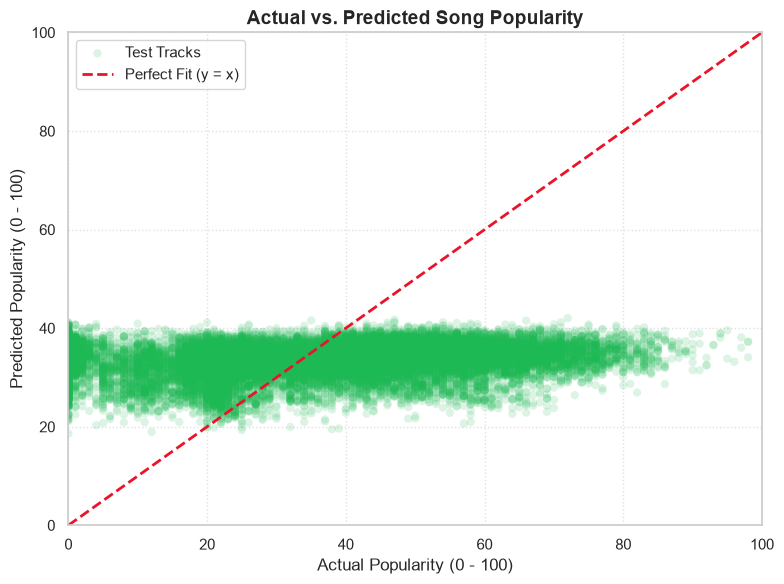

[Saved] Actual vs Predicted plot -> ..\outputs\actual_vs_predicted.png


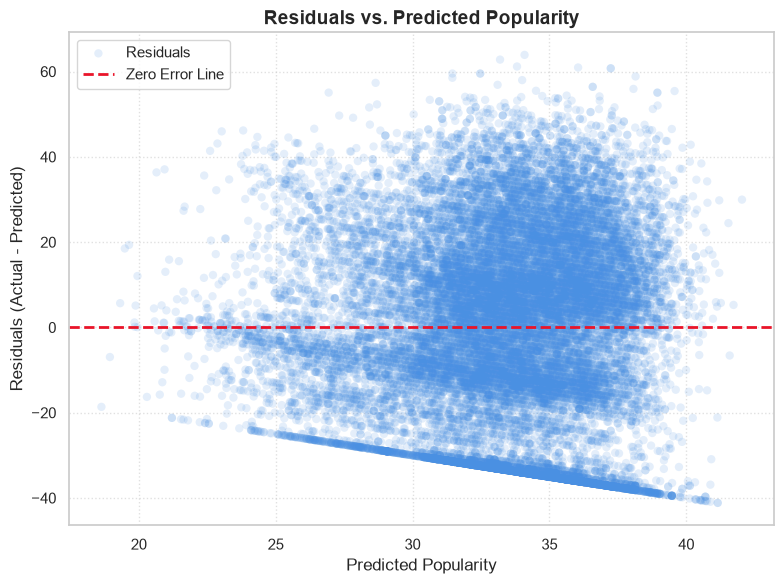

[Saved] Residual plot -> ..\outputs\residuals_plot.png


In [11]:
# 1. Actual vs Predicted Plot
plt.figure(figsize=(8, 6))
plt.scatter(y_test, y_pred, alpha=0.15, color="#1DB954", edgecolors="none", label="Test Tracks")
plt.plot([0, 100], [0, 100], color="#E91429", linestyle="--", linewidth=2, label="Perfect Fit (y = x)")
plt.title("Actual vs. Predicted Song Popularity", fontsize=14, weight="bold")
plt.xlabel("Actual Popularity (0 - 100)", fontsize=12)
plt.ylabel("Predicted Popularity (0 - 100)", fontsize=12)
plt.xlim(0, 100)
plt.ylim(0, 100)
plt.grid(True, linestyle=":", alpha=0.6)
plt.legend(loc="upper left")
plt.tight_layout()

actual_path = OUT_DIR / "actual_vs_predicted.png"
plt.savefig(actual_path, dpi=300)
plt.show()
print(f"[Saved] Actual vs Predicted plot -> {actual_path}")

# 2. Residual Plot
residuals = np.array(y_test) - np.array(y_pred)

plt.figure(figsize=(8, 6))
plt.scatter(y_pred, residuals, alpha=0.15, color="#4A90E2", edgecolors="none", label="Residuals")
plt.axhline(0, color="#E91429", linestyle="--", linewidth=2, label="Zero Error Line")
plt.title("Residuals vs. Predicted Popularity", fontsize=14, weight="bold")
plt.xlabel("Predicted Popularity", fontsize=12)
plt.ylabel("Residuals (Actual - Predicted)", fontsize=12)
plt.grid(True, linestyle=":", alpha=0.6)
plt.legend(loc="upper left")
plt.tight_layout()

residuals_path = OUT_DIR / "residuals_plot.png"
plt.savefig(residuals_path, dpi=300)
plt.show()
print(f"[Saved] Residual plot -> {residuals_path}")

## **Section 8: Empirical Takeaways & Pipeline Integration**
* **Lead:** **Aaditya Chandel** (Execution lead - Member 4)
* **Coding Task:** End-to-end integration and synthesis
* **Source Module:** `src/main.py`

### Key Scientific Takeaways:
1. **Acoustic Linear Limits ($R^2 \approx 0.0226$):** Audio features explain only $\approx 2.3\%$ of popularity variance. Predictions cluster horizontally between $25$ and $40$ around the dataset mean of $33.2$.
2. **Residual Structure:** The lower diagonal boundary ($0 - \hat{y} = -\hat{y}$) for tracks with zero popularity highlights non-linear bounds and heteroscedasticity.
3. **Core Conclusion:** Cultural and marketing factors (artist stardom, social media virality, playlist placement) dominate commercial success rather than acoustic frequencies alone.
4. **Integration Status:** Full pipeline runs headlessly via `python src/main.py` in under 3 seconds.